In [1]:

# Standard Libraries

import os
import gc
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")


# Data Manipulation

import numpy as np
import pandas as pd


# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")


# Machine Learning

from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    LabelEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# Deep Learning

import tensorflow as tf


# Miscellaneous

from tqdm import tqdm

# Data Validation & Exploratory Data Analysis (EDA)

## Goals

By the end of this section, we should be able to answer:

* What does our dataset look like?
* Is the target highly imbalanced?
* Which features are numerical/categorical?
* Which features have excessive missing values?
* Are there duplicate transactions?
* Which columns are constant or nearly constant?
* How are transaction amounts distributed?
* How does fraud vary over time?
* Which categories appear suspicious?
* Which features deserve further engineering?

---

# 2.1 Create a Data Quality Report

Let's build a reusable function instead of manually inspecting every column.

In [3]:
import os

DATA_DIR =  Path("data/raw")
# List the contents of the data/raw directory
print(f"Contents of {DATA_DIR}:")
for item in os.listdir(DATA_DIR):
    print(item)

Contents of data\raw:
merged.csv
sample_submission.csv
test_identity.csv
test_transaction.csv
train_identity.csv
train_transaction.csv


In [4]:
df = pd.read_csv(DATA_DIR/"Merged.csv")

In [5]:
# ============================================================
# Data Quality Report
# ============================================================

def data_quality_report(df):
    report = pd.DataFrame({
        "Data Type": df.dtypes,
        "Missing Values": df.isnull().sum(),
        "Missing (%)": (df.isnull().sum() / len(df) * 100).round(2),
        "Unique Values": df.nunique(),
        "Duplicate": [df[col].duplicated().sum() for col in df.columns]
    })

    report["Memory (KB)"] = (
        df.memory_usage(deep=True)[1:] / 1024
    ).values

    return report.sort_values("Missing (%)", ascending=False)

quality_report = data_quality_report(df)

quality_report.head(20)

,Data Type,Missing Values,Missing (%),Unique Values,Duplicate,Memory (KB)
id_24,float64,585793,99.20,12,590527,4613.593750
id_21,float64,585381,99.13,490,590049,4613.593750
id_07,float64,585385,99.13,84,590455,4613.593750
id_25,float64,585408,99.13,341,590198,4613.593750
id_26,float64,585377,99.13,95,590444,4613.593750
id_08,float64,585385,99.13,94,590445,4613.593750
id_27,str,585371,99.12,2,590537,18565.468750
id_23,str,585371,99.12,3,590536,18636.080078
id_22,float64,585371,99.12,25,590514,4613.593750
dist2,float64,552913,93.63,1751,588788,4613.593750


# 2.2 Dataset Summary

In [7]:
print("="*70)
print("DATASET SUMMARY")
print("="*70)

print(f"Rows                : {df.shape[0]:,}")
print(f"Columns             : {df.shape[1]}")

print(f"\nNumerical Features  : {len(df.select_dtypes(include=np.number).columns)}")
print(f"Categorical Features: {len(df.select_dtypes(include='object').columns)}")

print(f"\nDuplicate Rows      : {df.duplicated().sum()}")

print(f"\nMemory Usage        : {df.memory_usage(deep=True).sum()/1024**2:.2f} MB")

DATASET SUMMARY
Rows                : 590,540
Columns             : 434

Numerical Features  : 403
Categorical Features: 31

Duplicate Rows      : 0

Memory Usage        : 2513.97 MB


# 2.3 Target Distribution

Fraud detection datasets are almost always highly imbalanced. In the IEEE-CIS dataset, the positive class (`isFraud = 1`) represents only a small fraction of transactions, so understanding this imbalance is essential before choosing evaluation metrics or resampling strategies

In [8]:
fraud_counts = df["isFraud"].value_counts()

fraud_percent = (
    df["isFraud"]
    .value_counts(normalize=True)
    *100
)

display(pd.DataFrame({
    "Count": fraud_counts,
    "Percentage": fraud_percent.round(2)
}))

,Count,Percentage
isFraud,,
0,569877,96.5
1,20663,3.5


### Plot

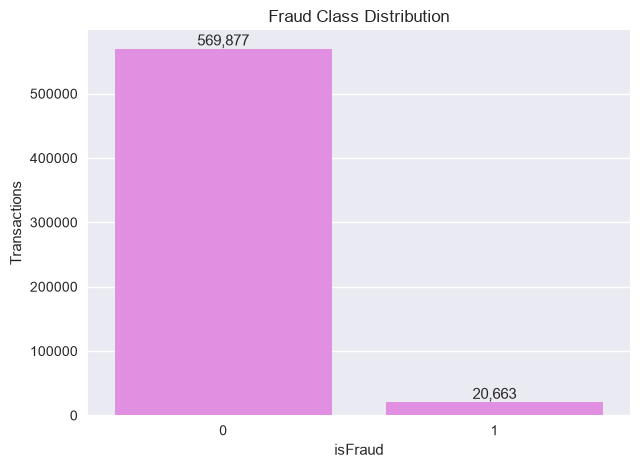

In [9]:
plt.figure(figsize=(7,5))

ax = sns.countplot(
    data=df,
    x="isFraud",
    color="violet"
)

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height()):,}",
        (p.get_x()+p.get_width()/2,
         p.get_height()),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title("Fraud Class Distribution")
plt.xlabel("isFraud")
plt.ylabel("Transactions")
plt.show()

# 2.4 Missing Values Analysis

Instead of immediately deleting columns with high missingness, let's quantify and visualize the extent of missing data. Identity-related fields in IEEE-CIS are intentionally absent for many transactions, and this missingness itself may carry predictive information.

In [10]:
missing = (
    df.isnull()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

missing = missing[missing > 0]

### Top Missing Features

In [11]:
missing.head(25)

id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_27    99.124699
id_23    99.124699
id_22    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
id_04    88.768923
id_03    88.768923
D6       87.606767
id_33    87.589494
id_09    87.312290
D8       87.312290
id_10    87.312290
D9       87.312290
id_30    86.865411
id_32    86.861855
dtype: float64

---

### Missing Value Plot

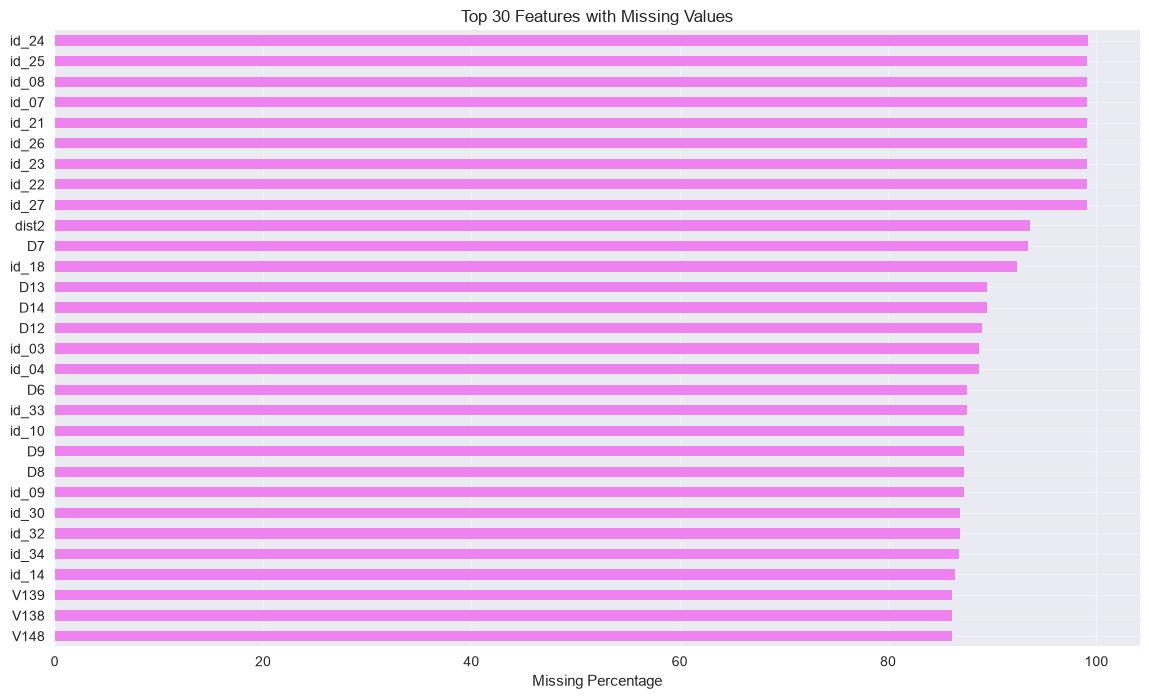

In [12]:
plt.figure(figsize=(14,8))

missing.head(30).sort_values().plot(kind="barh", color="violet")

plt.xlabel("Missing Percentage")

plt.title("Top 30 Features with Missing Values")

plt.grid(alpha=0.3)

plt.show()

---

# 2.5 Missing Value Categories

In [13]:
missing_df = pd.DataFrame({
    "Feature": missing.index,
    "Missing %": missing.values
})

bins = [0,20,40,60,80,100]

labels = [
    "0-20%",
    "20-40%",
    "40-60%",
    "60-80%",
    "80-100%"
]

missing_df["Category"] = pd.cut(
    missing_df["Missing %"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

missing_df["Category"].value_counts().sort_index()

Category
0-20%      162
20-40%      20
40-60%      24
60-80%     134
80-100%     74
Name: count, dtype: int64

# 2.6 Constant Features

Columns with only one unique value contain no predictive information and can safely be removed later.

In [14]:
constant_columns = [
    col
    for col in df.columns
    if df[col].nunique(dropna=False) == 1
]

print("Constant Features:", len(constant_columns))

constant_columns[:20]

Constant Features: 0


[]

# 2.7 Duplicate Transactions

In [15]:
duplicates = df.duplicated().sum()

print(f"Duplicate Rows : {duplicates:,}")

Duplicate Rows : 0


# 2.8 Transaction Amount Distribution

`TransactionAmt` represents the payment amount in USD and is one of the few interpretable numerical variables in the dataset. Financial transaction amounts are typically right-skewed with many small purchases and a few very large ones, so visualizing both the raw and log-transformed distributions is informative.

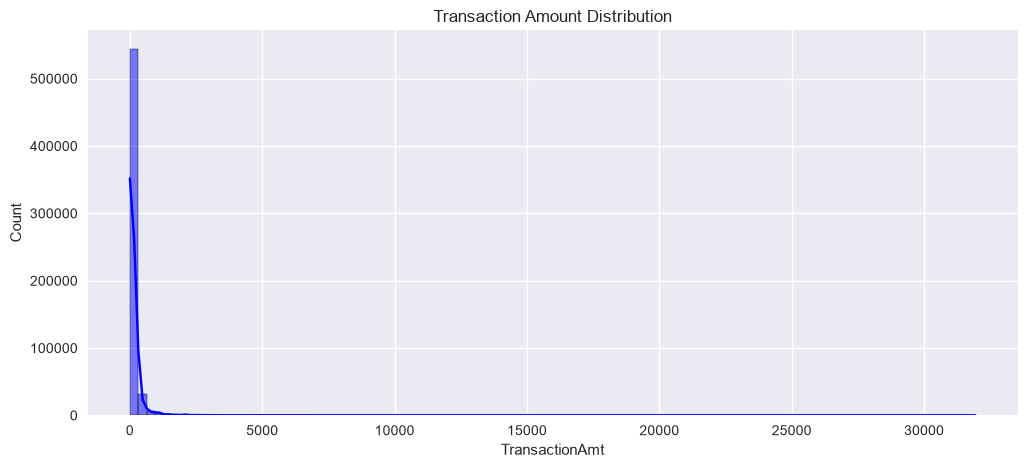

In [16]:
plt.figure(figsize=(12,5))

sns.histplot(
    df["TransactionAmt"],
    bins=100,
    kde=True,
    color="blue"
)

plt.title("Transaction Amount Distribution")

plt.show()

### Log Distribution

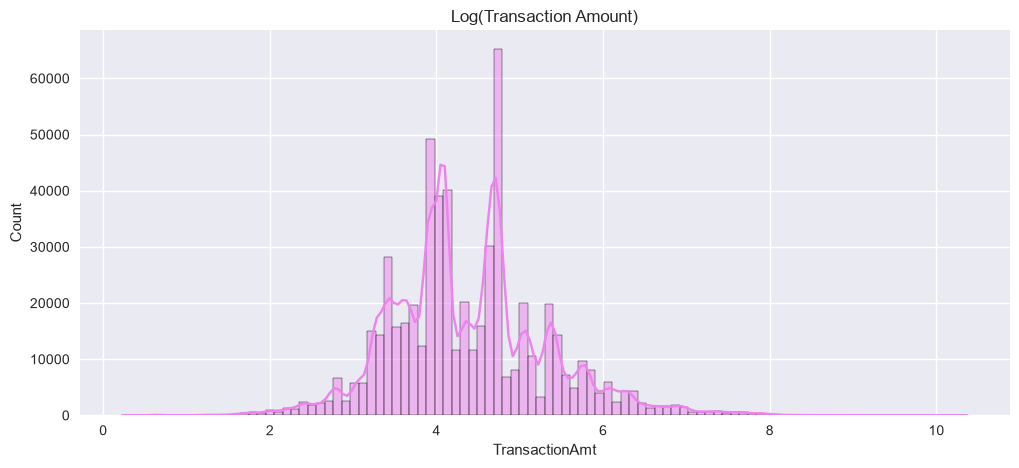

In [17]:
plt.figure(figsize=(12,5))

sns.histplot(
    np.log1p(df["TransactionAmt"]),
    bins=100,
    kde=True,
    color="violet"
)

plt.title("Log(Transaction Amount)")

plt.show()

# 2.9 Fraud vs Legitimate Transaction Amount

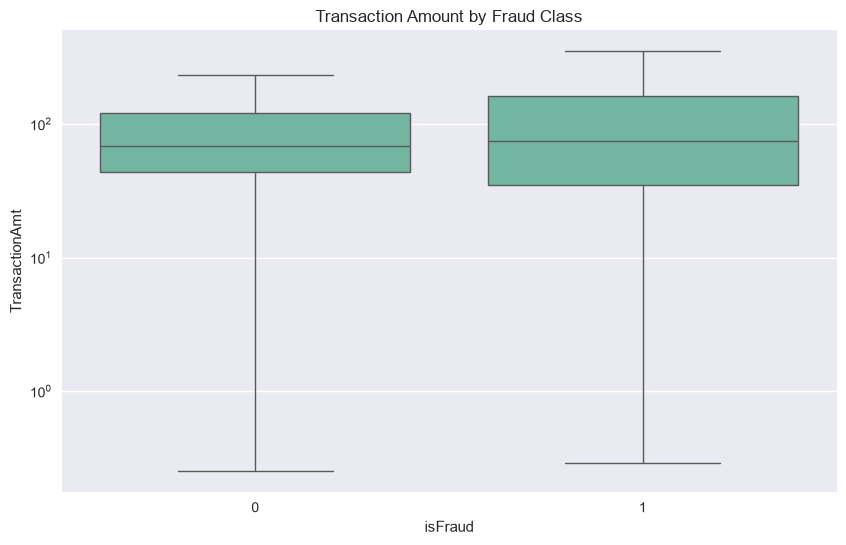

In [18]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="isFraud",
    y="TransactionAmt",
    showfliers=False
)

plt.yscale("log")

plt.title("Transaction Amount by Fraud Class")

plt.show()

# 2.10 Transaction Timeline

`TransactionDT` is **not an actual timestamp**; it represents the elapsed time from an internal reference point. Even so, it preserves the chronological order of transactions, making it valuable for temporal analysis and later for creating a time-aware train/validation split.

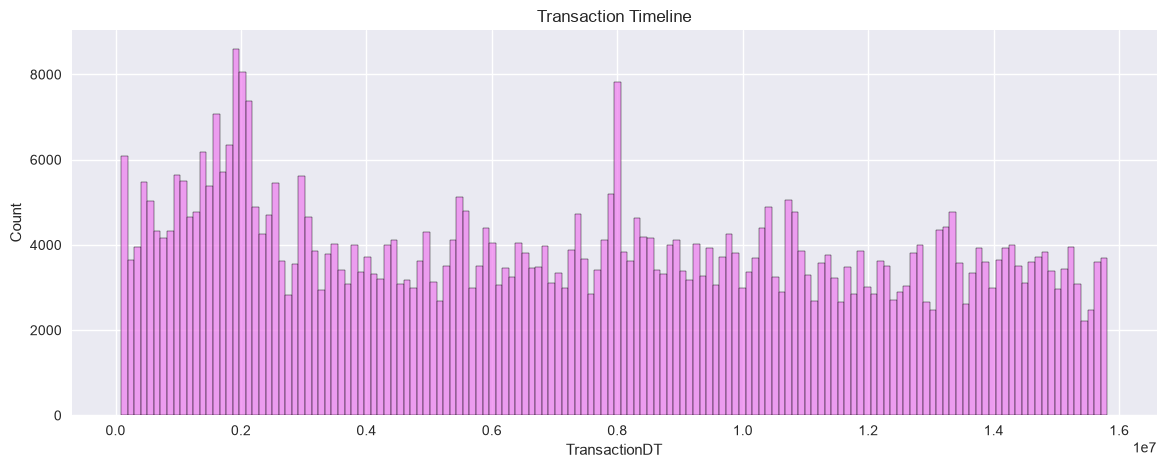

In [19]:
plt.figure(figsize=(14,5))

sns.histplot(
    df["TransactionDT"],
    bins=150,
    color='violet'
)

plt.title("Transaction Timeline")

plt.xlabel("TransactionDT")

plt.show()

# 2.11 Fraud Over Time

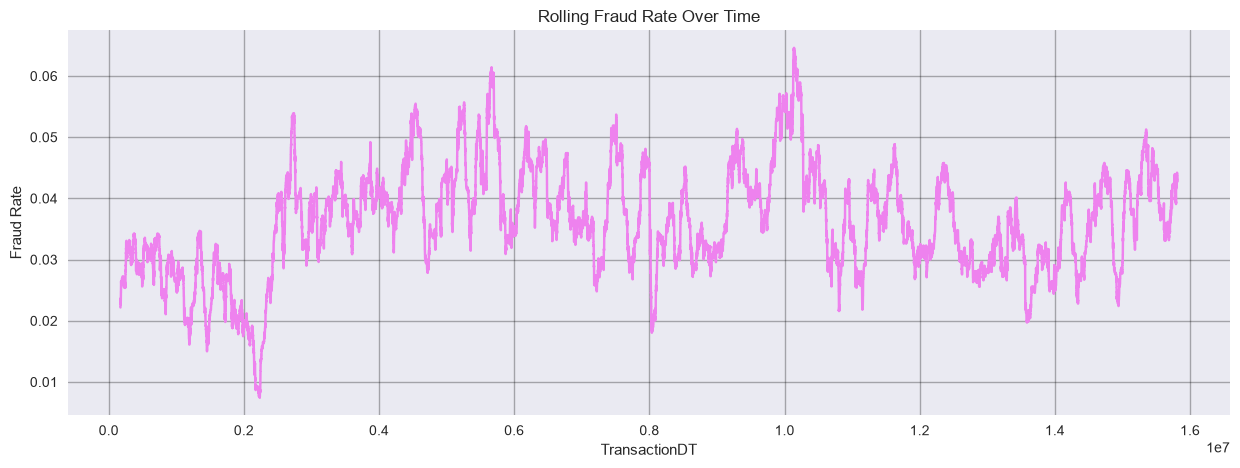

In [20]:
temp = (
    df.groupby("TransactionDT")["isFraud"]
      .mean()
      .rolling(5000)
      .mean()
)

plt.figure(figsize=(15,5))

plt.plot(temp, color="violet")

plt.title("Rolling Fraud Rate Over Time")

plt.xlabel("TransactionDT")

plt.ylabel("Fraud Rate")

plt.grid(alpha=0.3, color='black')

plt.show()

# Section 2.2 — Feature-wise Exploratory Data Analysis

---

# 2.2.1 Organize Features into Groups

This will make later analysis and preprocessing much cleaner.

In [21]:
# ============================================================
# Feature Groups
# ============================================================

card_features = [f"card{i}" for i in range(1, 7)]

addr_features = [
    "addr1",
    "addr2"
]

distance_features = [
    "dist1",
    "dist2"
]

email_features = [
    "P_emaildomain",
    "R_emaildomain"
]

match_features = [
    f"M{i}" for i in range(1,10)
]

count_features = [
    f"C{i}" for i in range(1,15)
]

timedelta_features = [
    f"D{i}" for i in range(1,16)
]

v_features = [
    col
    for col in df.columns
    if col.startswith("V")
]

id_features = [
    col
    for col in df.columns
    if col.startswith("id_")
]

identity_features = [
    "DeviceType",
    "DeviceInfo"
]

print(f"Card Features       : {len(card_features)}")
print(f"Address Features    : {len(addr_features)}")
print(f"Count Features      : {len(count_features)}")
print(f"Time Features       : {len(timedelta_features)}")
print(f"V Features          : {len(v_features)}")
print(f"Identity Features   : {len(id_features)}")

Card Features       : 6
Address Features    : 2
Count Features      : 14
Time Features       : 15
V Features          : 339
Identity Features   : 38


---

# 2.2.2 Fraud Rate by Product

Product code is one of the strongest interpretable variables.

In [22]:
product_stats = (
    df.groupby("ProductCD")
      .agg(
          Transactions=("isFraud","count"),
          FraudRate=("isFraud","mean")
      )
      .sort_values("FraudRate", ascending=False)
)

display(product_stats)

,Transactions,FraudRate
ProductCD,,
C,68519,0.116873
S,11628,0.058996
H,33024,0.047662
R,37699,0.037826
W,439670,0.020399


### Visualization

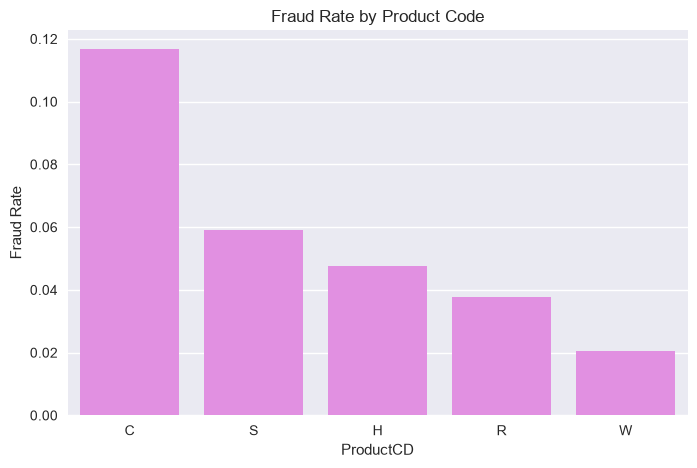

In [23]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=product_stats.reset_index(),
    x="ProductCD",
    y="FraudRate",
    color="violet"
)

plt.title("Fraud Rate by Product Code")

plt.ylabel("Fraud Rate")

plt.show()

You will likely observe that certain product categories exhibit substantially higher fraud rates than others, making `ProductCD` a valuable categorical feature for downstream models.

---

# 2.2.3 Payment Card Features

Let's inspect the payment card variables.

In [24]:
card_features

['card1', 'card2', 'card3', 'card4', 'card5', 'card6']

In [25]:
for feature in card_features:

    print("="*60)

    print(feature)

    display(
        df[feature]
        .value_counts(dropna=False)
        .head(10)
    )

    print()

card1


card1
7919     14932
9500     14162
15885    10361
17188    10344
15066     7945
12695     7091
12544     6773
6019      6771
2803      6141
7585      5334
Name: count, dtype: int64


card2


card2
321.0    48935
111.0    45191
555.0    41995
490.0    38145
583.0    21803
170.0    18214
194.0    16938
545.0    16355
360.0    15190
514.0    14541
Name: count, dtype: int64


card3


card3
150.0    521287
185.0     56346
106.0      1571
NaN        1565
144.0      1252
146.0      1252
117.0       962
143.0       899
119.0       750
102.0       460
Name: count, dtype: int64

... (2 outputs left out)


card5


card5
226.0    296546
224.0     81513
166.0     57140
102.0     29105
117.0     25941
138.0     19737
195.0     16945
137.0     11720
126.0     10298
219.0      9924
Name: count, dtype: int64


card6


card6
debit              439938
credit             148986
NaN                  1571
debit or credit        30
charge card            15
Name: count, dtype: int64

## Missing Values

In [26]:
card_missing = (
    df[card_features]
    .isnull()
    .mean()*100
)

card_missing

card1    0.000000
card2    1.512683
card3    0.265012
card4    0.267044
card5    0.721204
card6    0.266028
dtype: float64

# Fraud Rate by Card Type

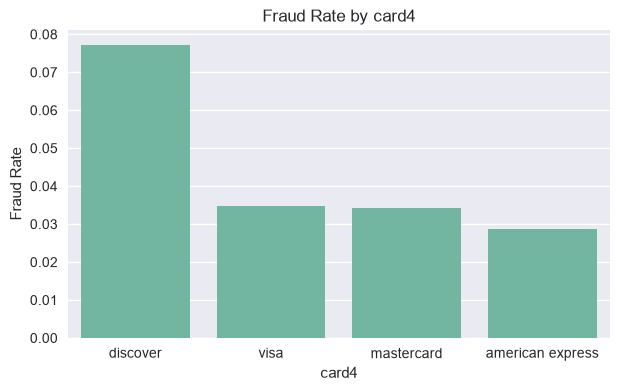

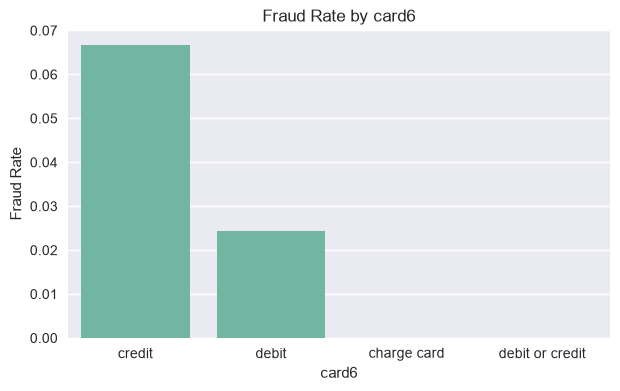

In [27]:
for feature in ["card4","card6"]:

    stats = (
        df.groupby(feature)["isFraud"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(7,4))

    sns.barplot(
        x=stats.index,
        y=stats.values
    )

    plt.title(f"Fraud Rate by {feature}")

    plt.ylabel("Fraud Rate")

    plt.show()

# 2.2.4 Address Features

In [28]:
for feature in addr_features:

    print(feature)

    print(df[feature].nunique())

    print(df[feature].isnull().mean()*100)

    print()

addr1
332
11.12642666034477

addr2
74
11.12642666034477



Fraud often clusters within certain billing regions or countries, making address variables useful despite being partially anonymized.




# 2.2.5 Email Domains

In [29]:
for feature in email_features:

    print("="*50)

    print(feature)

    display(
        df[feature]
        .value_counts()
        .head(15)
    )

P_emaildomain


P_emaildomain
gmail.com        228355
yahoo.com        100934
hotmail.com       45250
anonymous.com     36998
aol.com           28289
comcast.net        7888
icloud.com         6267
outlook.com        5096
msn.com            4092
att.net            4033
live.com           3041
sbcglobal.net      2970
verizon.net        2705
ymail.com          2396
bellsouth.net      1909
Name: count, dtype: int64

R_emaildomain


R_emaildomain
gmail.com        57147
hotmail.com      27509
anonymous.com    20529
yahoo.com        11842
aol.com           3701
outlook.com       2507
comcast.net       1812
yahoo.com.mx      1508
icloud.com        1398
msn.com            852
live.com           762
live.com.mx        754
verizon.net        620
me.com             556
sbcglobal.net      552
Name: count, dtype: int64

### Fraud Rate

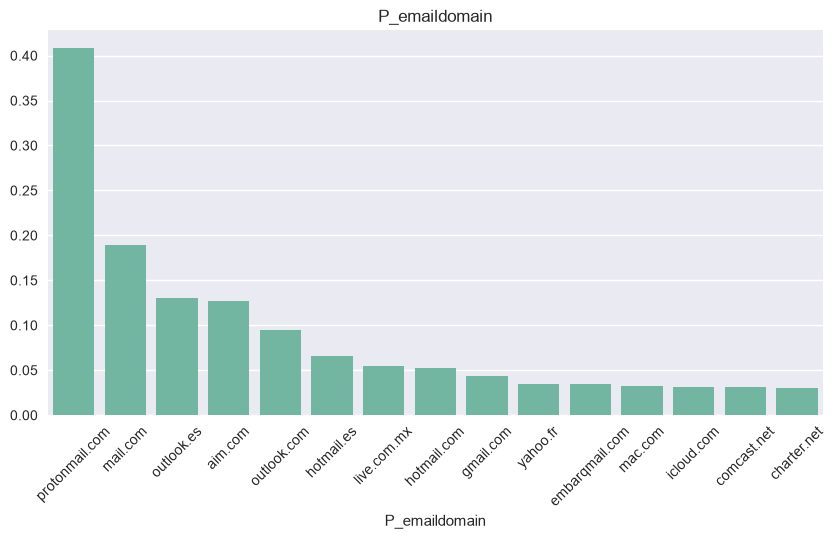

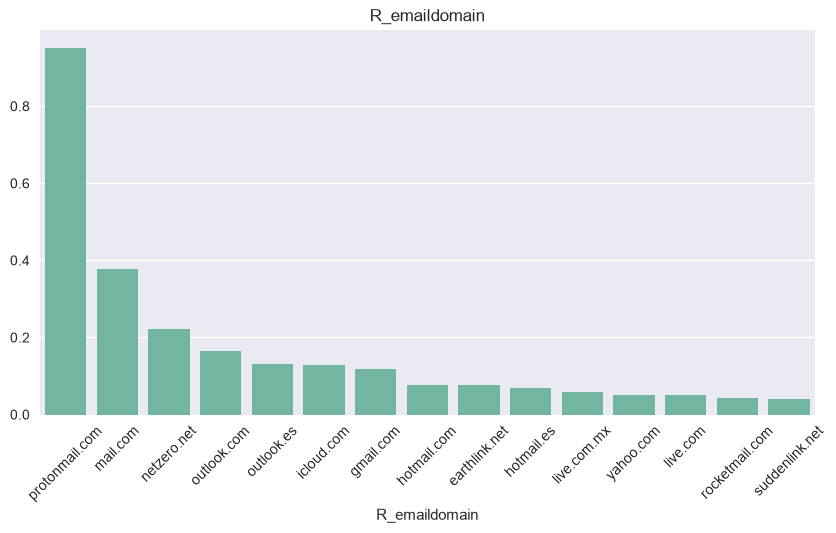

In [30]:
for feature in email_features:

    fraud_rate = (
        df.groupby(feature)["isFraud"]
          .mean()
          .sort_values(ascending=False)
          .head(15)
    )

    plt.figure(figsize=(10,5))

    sns.barplot(
        x=fraud_rate.index,
        y=fraud_rate.values
    )

    plt.xticks(rotation=45)

    plt.title(feature)

    plt.show()

# 2.2.6 Device Information

Identity information is available only for a subset of transactions, but device type and device information often contain strong fraud signals.

In [31]:
identity_features

['DeviceType', 'DeviceInfo']

In [32]:
for feature in identity_features:

    print(feature)

    display(
        df[feature]
        .value_counts(dropna=False)
        .head(20)
    )

    print()

DeviceType


DeviceType
NaN        449730
desktop     85165
mobile      55645
Name: count, dtype: int64


DeviceInfo


DeviceInfo
NaN                            471874
Windows                         47722
iOS Device                      19782
MacOS                           12573
Trident/7.0                      7440
rv:11.0                          1901
rv:57.0                           962
SM-J700M Build/MMB29K             549
SM-G610M Build/MMB29K             461
SM-G531H Build/LMY48B             410
rv:59.0                           362
SM-G935F Build/NRD90M             334
SM-G955U Build/NRD90M             328
SM-G532M Build/MMB29T             316
ALE-L23 Build/HuaweiALE-L23       312
SM-G950U Build/NRD90M             290
SM-G930V Build/NRD90M             274
rv:58.0                           269
rv:52.0                           256
SAMSUNG                           235
Name: count, dtype: int64

### Fraud Rate by Device Type

In [33]:
device_stats = (
    df.groupby("DeviceType")
      .agg(
          FraudRate=("isFraud","mean"),
          Count=("isFraud","count")
      )
)

display(device_stats)

,FraudRate,Count
DeviceType,,
desktop,0.065215,85165
mobile,0.101662,55645


# 2.2.7 Count Features (C1–C14)

These variables represent engineered count-related information created by Vesta (their exact semantics are intentionally masked). Rather than interpreting them individually, it's more useful to examine their distributions and relationships with fraud.

In [37]:
df[count_features].describe().T.head()

,count,mean,std,min,25%,50%,75%,max
C1,590540.0,14.092458,133.569018,0.0,1.0,1.0,3.0,4685.0
C2,590540.0,15.269734,154.668899,0.0,1.0,1.0,3.0,5691.0
C3,590540.0,0.005644,0.150536,0.0,0.0,0.0,0.0,26.0
C4,590540.0,4.092185,68.848459,0.0,0.0,0.0,0.0,2253.0
C5,590540.0,5.571526,25.786976,0.0,0.0,0.0,1.0,349.0


### Distribution

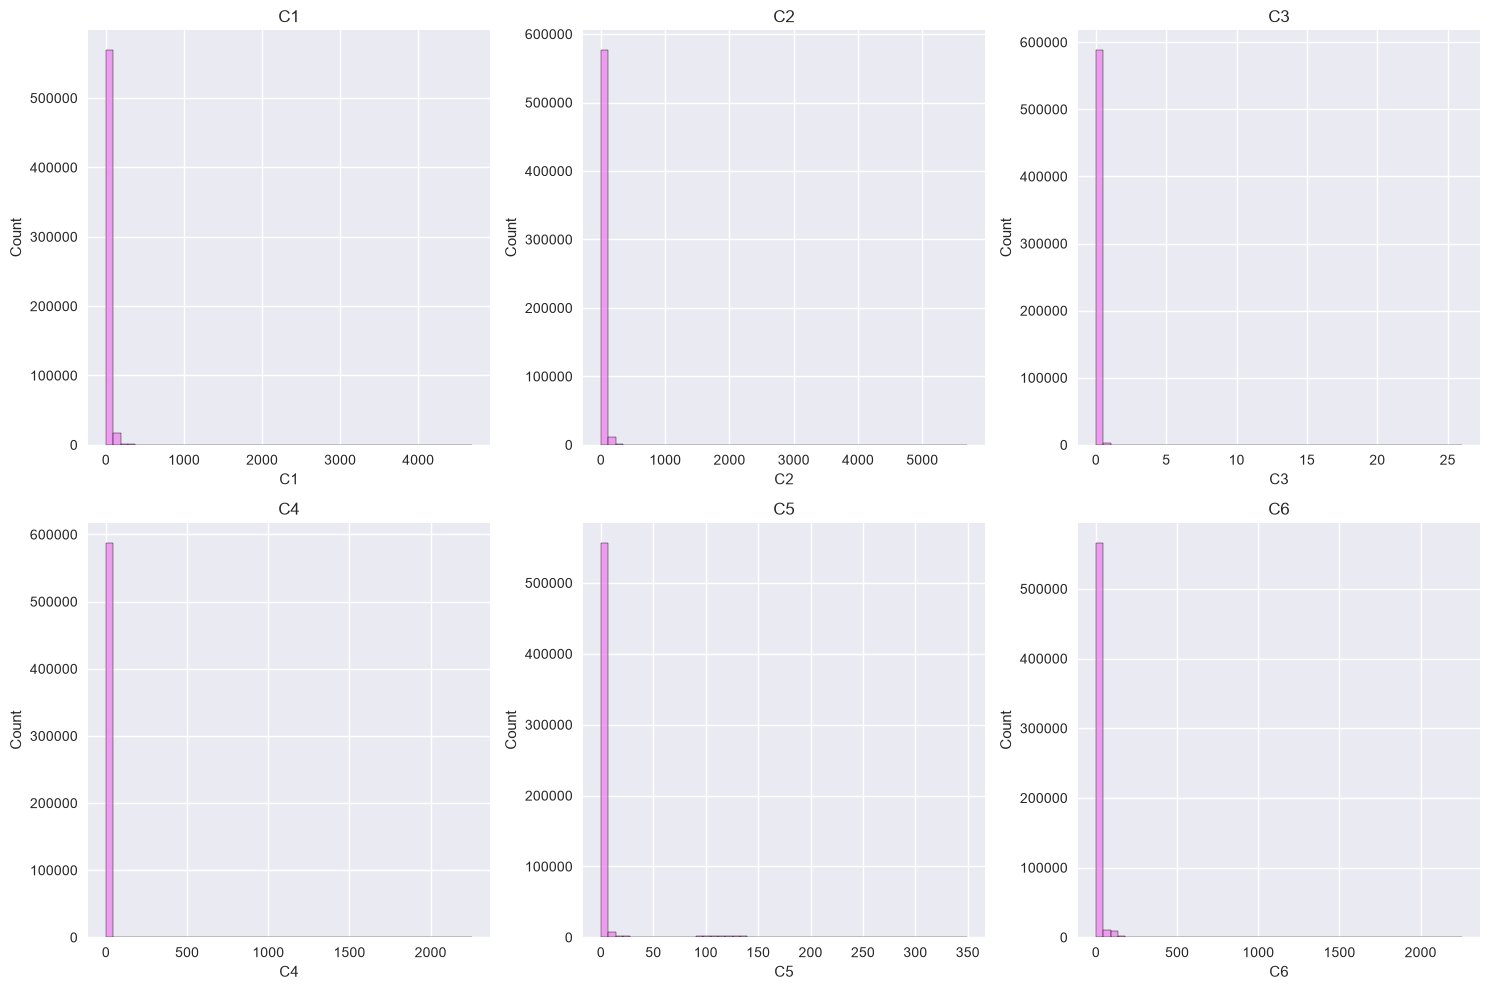

In [38]:
sample_features = count_features[:6]

plt.figure(figsize=(15,10))

for i, feature in enumerate(sample_features):

    plt.subplot(2,3,i+1)

    sns.histplot(
        df[feature],
        bins=50,
        color='violet'
    )

    plt.title(feature)

plt.tight_layout()

plt.show()

# 2.2.8 Time Delta Features (D1–D15)

These variables capture elapsed time relationships between transactions and are frequently among the most informative predictors in fraud detection models.

In [39]:
df[timedelta_features].describe().T

,count,mean,std,min,25%,50%,75%,max
D1,589271.0,94.347568,157.660387,0.0,0.000000,3.000000,122.000000,640.000000
D2,309743.0,169.563231,177.315865,0.0,26.000000,97.000000,276.000000,640.000000
D3,327662.0,28.343348,62.384721,0.0,1.000000,8.000000,27.000000,819.000000
D4,421618.0,140.002441,191.096774,-122.0,0.000000,26.000000,253.000000,869.000000
D5,280699.0,42.335965,89.000144,0.0,1.000000,10.000000,32.000000,819.000000
D6,73187.0,69.805717,143.669253,-83.0,0.000000,0.000000,40.000000,873.000000
D7,38917.0,41.638950,99.743264,0.0,0.000000,0.000000,17.000000,843.000000
D8,74926.0,146.058108,231.663840,0.0,0.958333,37.875000,187.958328,1707.791626
D9,74926.0,0.561057,0.316880,0.0,0.208333,0.666666,0.833333,0.958333
D10,514518.0,123.982137,182.615225,0.0,0.000000,15.000000,197.000000,876.000000


### Missing Values

In [40]:
(
    df[timedelta_features]
    .isnull()
    .mean()
    .sort_values(ascending=False)
    *100
)

D7     93.409930
D13    89.509263
D14    89.469469
D12    89.041047
D6     87.606767
D8     87.312290
D9     87.312290
D5     52.467403
D2     47.549192
D11    47.293494
D3     44.514851
D4     28.604667
D15    15.090087
D10    12.873302
D1      0.214888
dtype: float64

# 2.2.9 Correlation Analysis

Instead of computing correlations across all 430+ features, which is computationally expensive and difficult to interpret, we'll focus on the most informative numerical variables.

In [41]:
selected = [
    "TransactionAmt",
    "TransactionDT",
    "isFraud"
] + count_features + timedelta_features

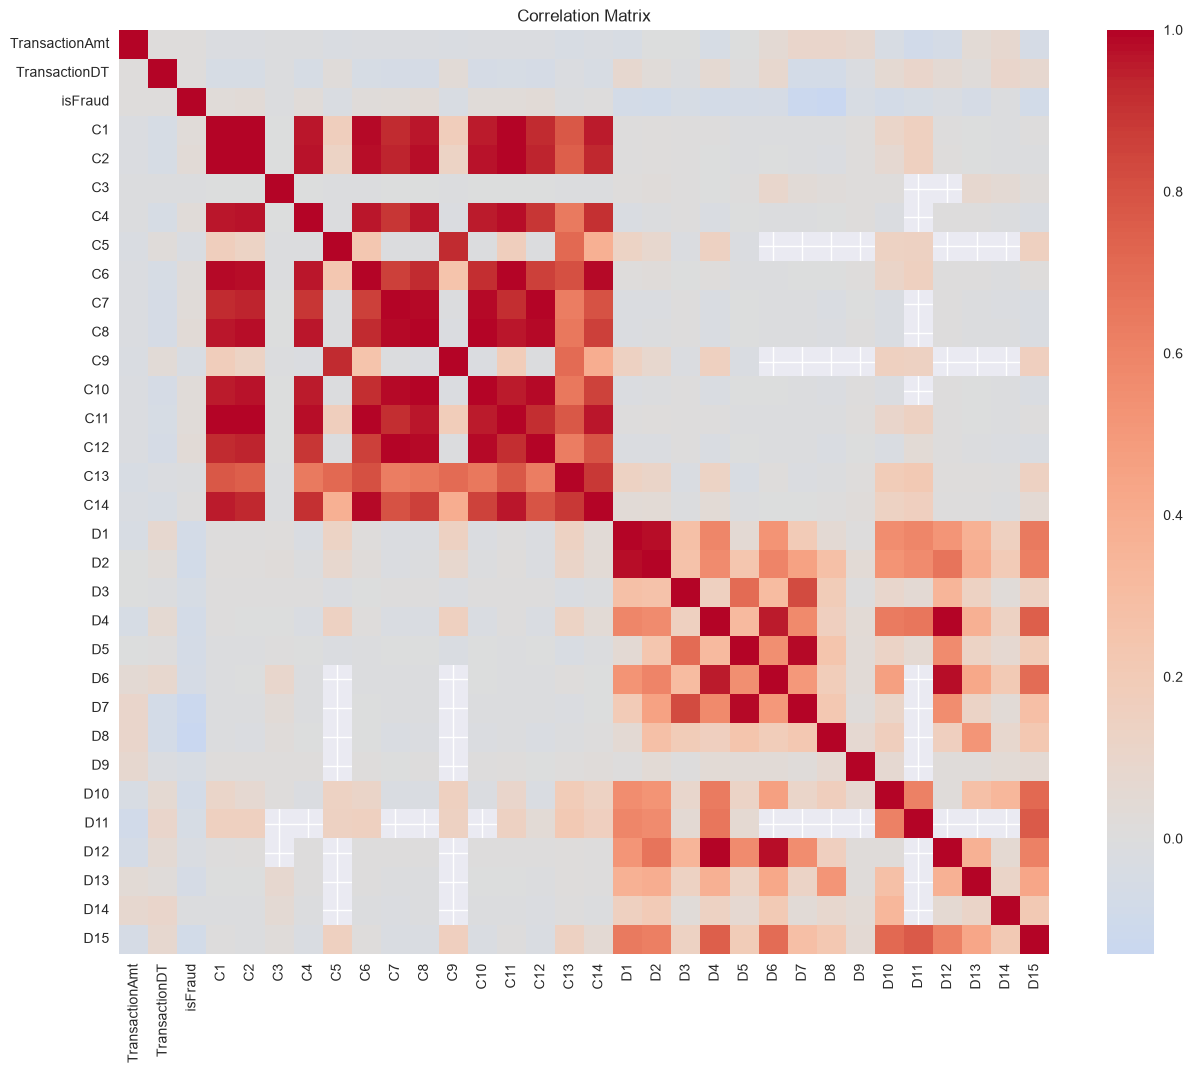

In [42]:
corr = df[selected].corr(numeric_only=True)

plt.figure(figsize=(15,12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")

plt.show()

# 2.2.10 Highly Correlated Features

In [43]:
corr_matrix = (
    df
    .select_dtypes(include=np.number)
    .corr()
    .abs()
)

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr = [
    column
    for column in upper.columns
    if any(upper[column] > 0.98)
]

print(f"Highly Correlated Features : {len(high_corr)}")

Highly Correlated Features : 71


We are only identifying them at this stage. We will decide later whether to remove them after considering model choice, since tree-based models are generally less sensitive to multicollinearity than linear models.



# End of EDA

At this point we have:

* ✓ Understood the target imbalance
* ✓ Quantified missing values
* ✓ Explored transaction amount and temporal behavior
* ✓ Investigated product, payment card, address, email, and device features
* ✓ Examined engineered feature groups (`C` and `D`)
* ✓ Identified highly correlated variables for later consideration


This is where most beginners make mistakes.
They immediately call:
```py
df.fillna(0)
```
or
```py
df.dropna()
```

without understanding what they're doing.

For a production ML system, every preprocessing decision should have a justification.



In [44]:
df.to_csv(DATA_DIR / 'features_df.csv', index=False)
print("Highly corrilated features are save in features_df.csv")

Highly corrilated features are save in features_df.csv


In [46]:
import gc

def reset_memory():
    # Delete all variables.
    for var in gc.get_objects():
        try:
            del var
        except:
            pass

    # Run the garbage collector.
    gc.collect()

    print("Memory has been reset")


In [53]:
reset_memory()

Memory has been reset


In [52]:
plt.close("all")

In [50]:
del df

In [51]:
import gc

gc.collect()

0